# Support Vector Machines: Classifying Iris Species

The classic Iris dataset (Fisher, 1936): 150 flowers from three species (*setosa*, *versicolor*, *virginica*),
each described by sepal and petal length and width. I train an SVM classifier and tune it with a grid search.

**Tools:** pandas, seaborn, scikit-learn (`SVC`, `GridSearchCV`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style('whitegrid')

## 1. Data

In [2]:
iris = pd.read_csv('data/iris.csv')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


## 2. Exploratory analysis

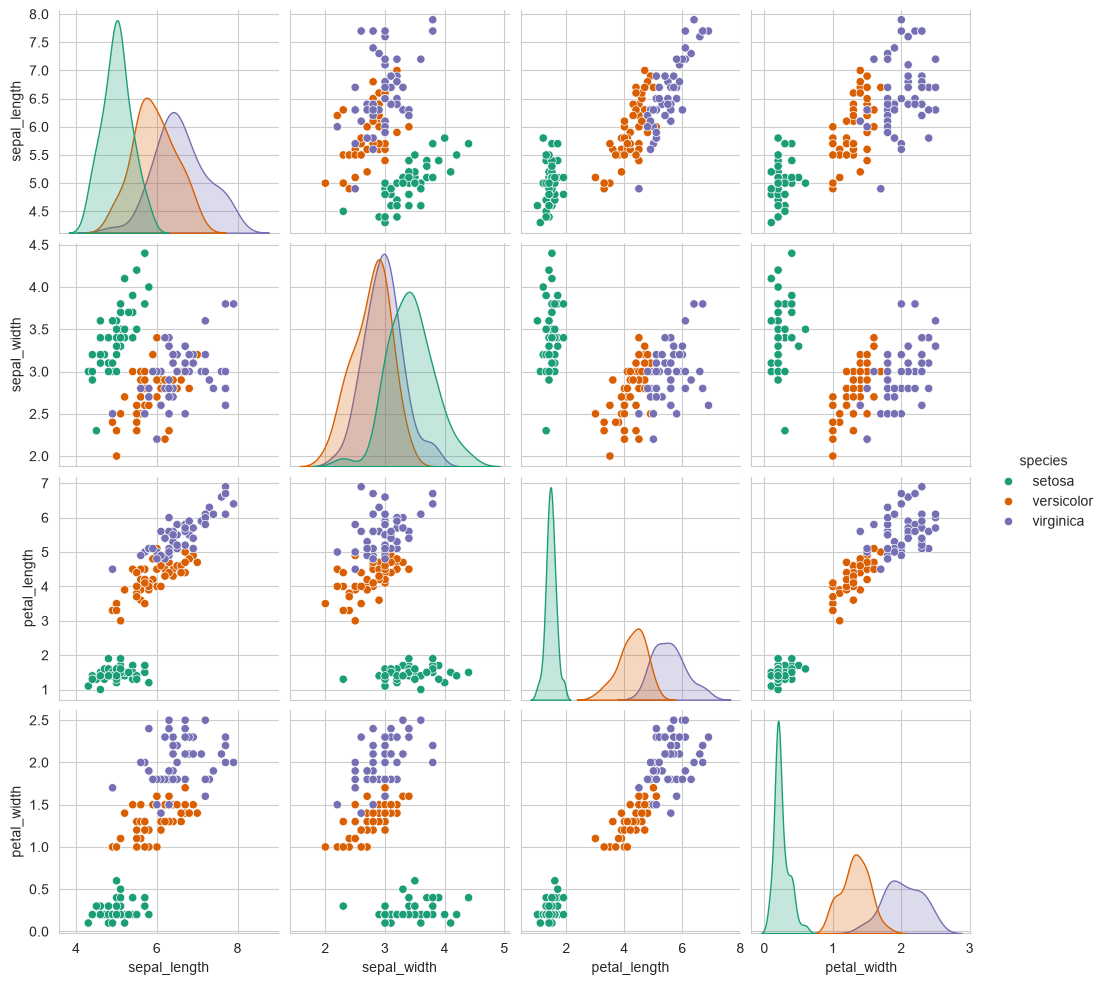

In [4]:
sns.pairplot(data=iris, hue='species', palette='Dark2')

*Setosa* is clearly separable from the other two species; *versicolor* and *virginica* overlap slightly.

<Axes: xlabel='sepal_width', ylabel='sepal_length'>

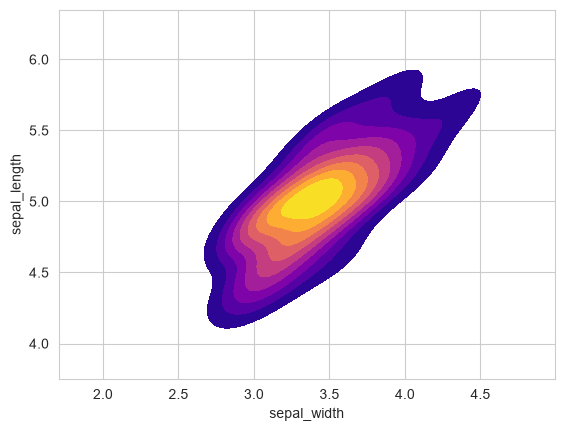

In [5]:
setosa = iris[iris['species'] == 'setosa']
sns.kdeplot(data=setosa, x='sepal_width', y='sepal_length', cmap='plasma', fill=True, thresh=0.1)

## 3. Train / test split

In [6]:
from sklearn.model_selection import train_test_split

X = iris.drop('species', axis=1)
y = iris['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

## 4. SVM with default parameters

In [7]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

svc_model = SVC(gamma='auto')
svc_model.fit(X_train, y_train)
predictions = svc_model.predict(X_test)

print(confusion_matrix(y_test, predictions))
print()
print(classification_report(y_test, predictions))

[[13  0  0]
 [ 0 20  0]
 [ 0  0 12]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       1.00      1.00      1.00        20
   virginica       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



## 5. Hyper-parameter tuning with GridSearchCV

`C` controls how strongly misclassifications are penalised, `gamma` controls how far the influence of one training point reaches (RBF kernel). Each combination is evaluated with 5-fold cross-validation.

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.1, 1, 10, 100, 1000], 'gamma': [1, 0.1, 0.01, 0.001, 0.0001]}
grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=0)
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best cross-validation accuracy:', round(grid.best_score_, 3))

Best parameters: {'C': 1, 'gamma': 0.1}
Best cross-validation accuracy: 0.962


In [9]:
grid_predictions = grid.predict(X_test)
print(confusion_matrix(y_test, grid_predictions))
print()
print(classification_report(y_test, grid_predictions))

[[13  0  0]
 [ 0 19  1]
 [ 0  0 12]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       1.00      0.95      0.97        20
   virginica       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



## 6. Conclusion

- The default SVM classifies all 45 test flowers correctly (100%).
- Grid search picks `C=1, gamma=0.1` with 96% cross-validated accuracy; on the test set it misclassifies one *versicolor* as *virginica* (98%).
- Tuning does not help here because the dataset is small and almost linearly separable, and a 45-flower test set
  is too small to tell a 98% model from a 100% model. The cross-validation score is the more trustworthy estimate.
- The only errors happen between *versicolor* and *virginica*, which is exactly where the pairplot shows overlap.